**Data 620 - Project 3**\
Yana Rabkova

**Introduction**

Video link presentation: https://youtu.be/kCUITXzIIsg 

For this assignment, we are working with the NLTK Names Corpus, which contains names labeled as male or female. The goal is to build a machine learning classifier that predicts gender labels based on different characteristics of names, such as their first and last letters, suffixes, and length.

I used both NLTK and scikit-learn to implement Naive Bayes classifiers and experiment with different combinations of features to improve classification accuracy. 

In [ ]:
import random

import nltk
from nltk.corpus import names

nltk.download('names')

# Create labeled dataset
labeled_names = (
    [(name, 'male') for name in names.words('male.txt')] +
    [(name, 'female') for name in names.words('female.txt')]
)

# Shuffle for reproducibility
random.seed(42)
random.shuffle(labeled_names)

# Split the dataset
test_names = labeled_names[:500]
devtest_names = labeled_names[500:1000]
train_names = labeled_names[1000:7900]

print("Total names:", len(labeled_names))
print("Training:", len(train_names))
print("Dev-test:", len(devtest_names))
print("Test:", len(test_names))


Total names: 7944
Training: 6900
Dev-test: 500
Test: 500


[nltk_data] Downloading package names to
[nltk_data]     /Users/yanarabkova/nltk_data...
[nltk_data]   Package names is already up-to-date!


In [31]:
import pandas as pd

# Create a DataFrame for each subset
train_df = pd.DataFrame(train_names, columns=['name', 'gender'])
devtest_df = pd.DataFrame(devtest_names, columns=['name', 'gender'])
test_df = pd.DataFrame(test_names, columns=['name', 'gender'])

# Calculate class distribution
class_balance = pd.DataFrame({
    'Training': train_df['gender'].value_counts(normalize=True) * 100,
    'Dev-test': devtest_df['gender'].value_counts(normalize=True) * 100,
    'Test': test_df['gender'].value_counts(normalize=True) * 100
}).round(2)

print("Gender Distribution (%):")
print(class_balance)

Gender Distribution (%):
        Training  Dev-test  Test
gender                          
female     63.23      59.4  63.2
male       36.77      40.6  36.8


In [32]:
# Baseline model, similar to the book, they are using only the last letter of each name
def gender_features(name):
    return {'last_letter': name[-1].lower()}

train_set = [
    (gender_features(name), gender)
    for name, gender in train_names
]

devtest_set = [
    (gender_features(name), gender)
    for name, gender in devtest_names
]

classifier = nltk.NaiveBayesClassifier.train(train_set)

baseline_accuracy = nltk.classify.accuracy(
    classifier, devtest_set
)

print(f"Baseline accuracy: {baseline_accuracy:.3f}")

Baseline accuracy: 0.754


The baseline classifier achieved 75.4% accuracy on the development-test set using only the last letter of each name as a predictive feature. 

In [33]:
import pandas as pd

df = pd.DataFrame(
    train_names,
    columns=['name', 'gender']
)

df['last_letter'] = df['name'].str.lower().str[-1]

ending_distribution = pd.crosstab(
    df['last_letter'],
    df['gender'],
    normalize='index'
).round(3)

print(ending_distribution)

gender       female   male
last_letter               
              1.000  0.000
a             0.982  0.018
b             0.333  0.667
c             0.000  1.000
d             0.150  0.850
e             0.756  0.244
f             0.042  0.958
g             0.243  0.757
h             0.541  0.459
i             0.868  0.132
j             0.250  0.750
k             0.050  0.950
l             0.497  0.503
m             0.160  0.840
n             0.450  0.550
o             0.160  0.840
p             0.056  0.944
r             0.197  0.803
s             0.275  0.725
t             0.285  0.715
u             0.353  0.647
v             0.143  0.857
w             0.263  0.737
x             0.526  0.474
y             0.586  0.414
z             0.250  0.750


The distribution of last letters shows that certain endings are strongly associated with gender. For example, 98.2% of names ending in *a* are female-labeled, while names ending in *k* (95.0%) and *f* (95.8%) are predominantly male-labeled.

However, some letters, such as *n*, *l*, and *h*, have nearly equal distributions between male and female labels, making them less useful for classification on their own.

These findings suggest that the last letter is a useful predictor, but additional features, such as two-letter endings, may help distinguish names with more ambiguous endings. We will explore these features in the following models to see whether they improve classification accuracy.

In [34]:
#Model 2, using the first and last letter
def gender_features_v2(name):
    name = name.lower()
    return {
        'first_letter': name[0],
        'last_letter': name[-1]
    }

train_set_v2 = [
    (gender_features_v2(name), gender)
    for name, gender in train_names
]

devtest_set_v2 = [
    (gender_features_v2(name), gender)
    for name, gender in devtest_names
]

classifier_v2 = nltk.NaiveBayesClassifier.train(train_set_v2)

accuracy_v2 = nltk.classify.accuracy(
    classifier_v2, devtest_set_v2
)

print(f"Baseline accuracy: {baseline_accuracy:.3f}")
print(f"Model 2 accuracy: {accuracy_v2:.3f}")

Baseline accuracy: 0.754
Model 2 accuracy: 0.754


Model 2 included both the first and last letters of each name. However, accuracy remained unchanged at 75.4%, suggesting that adding the first letter did not provide additional predictive value in this model. Next, we will explore whether using the last two letters improves classification performance.

In [35]:
#Model 3, using two last letters
def gender_features_v3(name):
    name = name.lower()
    return {
        'last_two_letters': name[-2:]
    }

train_set_v3 = [
    (gender_features_v3(name), gender)
    for name, gender in train_names
]

devtest_set_v3 = [
    (gender_features_v3(name), gender)
    for name, gender in devtest_names
]

classifier_v3 = nltk.NaiveBayesClassifier.train(train_set_v3)

accuracy_v3 = nltk.classify.accuracy(
    classifier_v3, devtest_set_v3
)

print(f"Model 1(baseline, one last letter): {baseline_accuracy:.3f}")
print(f"Model 2(first and last letter): {accuracy_v2:.3f}")
print(f"Model 3(two last letters): {accuracy_v3:.3f}")

Model 1(baseline, one last letter): 0.754
Model 2(first and last letter): 0.754
Model 3(two last letters): 0.756


In [36]:
def gender_features_v4(name):
    name = name.lower()
    return {
        'last_letter': name[-1],
        'last_two_letters': name[-2:]
    }

train_set_v4 = [
    (gender_features_v4(name), gender)
    for name, gender in train_names
]

devtest_set_v4 = [
    (gender_features_v4(name), gender)
    for name, gender in devtest_names
]

classifier_v4 = nltk.NaiveBayesClassifier.train(train_set_v4)

accuracy_v4 = nltk.classify.accuracy(
    classifier_v4, devtest_set_v4
)

print(f"Model 1(baseline, one last letter): {baseline_accuracy:.3f}")
print(f"Model 2(first and last letter): {accuracy_v2:.3f}")
print(f"Model 3(two last letters): {accuracy_v3:.3f}")
print(f"Model 4(one last letter + two last letters: {accuracy_v4:.3f}")

Model 1(baseline, one last letter): 0.754
Model 2(first and last letter): 0.754
Model 3(two last letters): 0.756
Model 4(one last letter + two last letters: 0.780


Models 3 and 4 explored different combinations of name endings. Model 3, using only the last two letters, showed a slight improvement to 75.6%. However, combining the last letter with the last two letters in Model 4 increased accuracy to 78.0%.

These results suggest that combining suffix features provides more predictive information than using either feature alone. Next, we will investigate whether adding name length can further improve classification accuracy.

In [37]:
def gender_features_v5(name):
    name = name.lower()
    return {
        'last_letter': name[-1],
        'last_two_letters': name[-2:],
        'name_length': len(name)
    }

train_set_v5 = [
    (gender_features_v5(name), gender)
    for name, gender in train_names
]

devtest_set_v5 = [
    (gender_features_v5(name), gender)
    for name, gender in devtest_names
]

classifier_v5 = nltk.NaiveBayesClassifier.train(train_set_v5)

accuracy_v5 = nltk.classify.accuracy(
    classifier_v5, devtest_set_v5
)

print(f"Model 4(one last letter + two last letters: {accuracy_v4:.3f}")
print(f"Model 5 accuracy(Model 4 + name length): {accuracy_v5:.3f}")

Model 4(one last letter + two last letters: 0.780
Model 5 accuracy(Model 4 + name length): 0.780


#### Scikit-Learn Multinomial Naive Bayes classifier

In [ ]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

feature_functions = {
    "Model 1": gender_features,
    "Model 2": gender_features_v2,
    "Model 3": gender_features_v3,
    "Model 4": gender_features_v4,
    "Model 5": gender_features_v5
}

results = []
trained_models = {}

y_train = [gender for name, gender in train_names]
y_dev = [gender for name, gender in devtest_names]

for model_name, feature_func in feature_functions.items():

    X_train = [feature_func(name) for name, gender in train_names]
    X_dev = [feature_func(name) for name, gender in devtest_names]

    model = make_pipeline(
        DictVectorizer(),
        MultinomialNB()
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_dev)
    accuracy = accuracy_score(y_dev, predictions)

    trained_models[model_name] = model

    results.append({
        "Model": model_name,
        "Dev-test Accuracy": accuracy
    })

results_df = pd.DataFrame(results)

print(results_df)

     Model  Dev-test Accuracy
0  Model 1              0.754
1  Model 2              0.754
2  Model 3              0.756
3  Model 4              0.784
4  Model 5              0.788


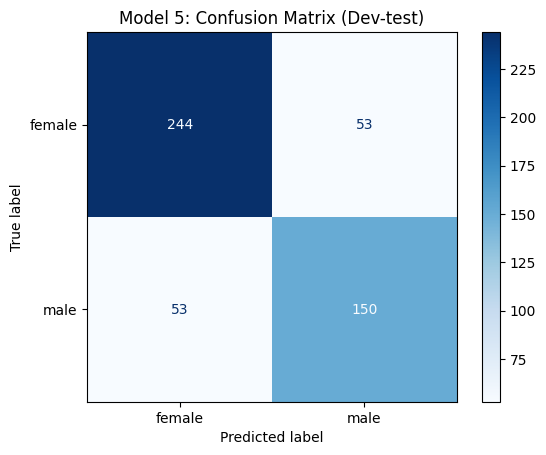

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Predictions from Model 5
y_pred_v5 = trained_models["Model 5"].predict(
    [gender_features_v5(name) for name, gender in devtest_names]
)

ConfusionMatrixDisplay.from_predictions(
    y_dev,
    y_pred_v5,
    labels=['female', 'male'],
    cmap='Blues'
)

plt.title('Model 5: Confusion Matrix (Dev-test)')
plt.show()

To ensure a consistent comparison, all five feature configurations were evaluated using scikit-learn's Multinomial Naive Bayes classifier. The models were trained on the same training set and evaluated on the development-test set.

Model 5, which included the last letter, last two letters, and name length, achieved the highest development-test accuracy of 78.8%. The confusion matrix for Model 5 shows that the classifier correctly predicted 394 out of 500 names, achieving 78.8% accuracy. The model performed better for female-labeled names (82.2% recall) than male-labeled names (73.9% recall).

Interestingly, the classifier made the same number of errors for both classes (53 each). However, because the dataset contains fewer male-labeled names, the proportion of incorrect predictions was higher for that class. This difference may be partly related to the class imbalance observed earlier.

In [40]:
# Select the best model
best_model = trained_models["Model 5"]

# Prepare test features
X_test = [
    gender_features_v5(name)
    for name, gender in test_names
]

y_test = [
    gender
    for name, gender in test_names
]

# Final evaluation
test_predictions = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Dev-test accuracy: {results_df.iloc[4]['Dev-test Accuracy']:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

Dev-test accuracy: 0.788
Test accuracy: 0.774


In [41]:

# Extract vectorizer and classifier
vectorizer = best_model.named_steps['dictvectorizer']
nb = best_model.named_steps['multinomialnb']

# Get feature names
feature_names = vectorizer.get_feature_names_out()

# Compare log probabilities for each gender
female_idx = list(nb.classes_).index('female')
male_idx = list(nb.classes_).index('male')

log_prob_diff = (
    nb.feature_log_prob_[female_idx] -
    nb.feature_log_prob_[male_idx]
)

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Female_vs_Male': log_prob_diff
})

# Most female-associated features
print("Top 10 Female-Associated Features:")
print(
    feature_importance
    .sort_values('Female_vs_Male', ascending=False)
    .head(10)
)

# Most male-associated features
print("\nTop 10 Male-Associated Features:")
print(
    feature_importance
    .sort_values('Female_vs_Male')
    .head(10)
)

Top 10 Female-Associated Features:
                 Feature  Female_vs_Male
175  last_two_letters=na        4.315063
65   last_two_letters=da        4.188379
154  last_two_letters=la        3.929028
1          last_letter=a        3.412858
123  last_two_letters=ia        3.405081
241  last_two_letters=ta        3.201786
233  last_two_letters=sa        3.148361
213  last_two_letters=ra        3.025229
57   last_two_letters=ca        2.931297
167  last_two_letters=ma        2.612843

Top 10 Male-Associated Features:
                 Feature  Female_vs_Male
61   last_two_letters=ck       -4.176129
3          last_letter=c       -3.656253
216  last_two_letters=rd       -3.509650
189  last_two_letters=od       -3.398424
125  last_two_letters=ic       -3.273261
11         last_letter=k       -3.239359
265  last_two_letters=us       -3.221968
246  last_two_letters=to       -3.204268
6          last_letter=f       -3.050117
62   last_two_letters=co       -3.050117


Feature analysis revealed that suffixes were strongly associated with gender classification. Female-labeled names were particularly associated with endings such as *-na*, *-da*, *-la*, and *-ia*, while male-labeled names were associated with endings such as *-ck*, *-rd*, *-ic*, and *-us*.

These findings were consistent with the exploratory analysis, which showed that names ending in *a* were predominantly female-labeled. The results also help explain why combining one- and two-letter endings improved classification accuracy compared with using either feature independently.

**Conclusion**

The final model achieved 77.4% accuracy on the independent test set, compared with 78.8% on the development-test set. This small decrease was expected because the development-test set was used for model selection, while the test set remained unseen during development.

Overall, the results suggest that name endings are useful predictors of gender labels and that combining multiple features can improve classification performance. The relatively small difference between development-test and test accuracy suggests that the final model generalizes reasonably well to unseen names.